# Reversal pe volume bars: model de atingere a barierelor și meta-labeling

**`btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · bare de volum `volume_adapt60s` · triple barrier · train iulie 2025 – aprilie 2026, test mai – octombrie 2026 · `EXPLORATORY`

## Rezumat

**Întrebare.** O strategie simplă de reversal, filtrată de un model care prezice dacă TP sau SL va fi atins (un model de volatilitate), sau de un meta-model care prezice dacă tranzacția va fi profitabilă: devine mai bună?

**Răspuns: nu.** Modelul de atingere funcționează ca model (AUC 0,64 pe test, acuratețe 0,60 față de 0,53 prin ghicire). Dar tranzacțiile pe care le selectează **nu sunt mai bune**: randamentul brut pe tranzacție scade de la +3,8 la +2,2 bps, sub 80% dintre filtrele aleatoare de aceeași mărime. Meta-modelul este mai slab decât hazardul pe test (AUC 0,45). Nicio variantă nu este profitabilă după costuri de 4 sau 10 bps.

| Întrebare | Rezultat (test, mai–octombrie 2026, 501 semnale) |
|---|---|
| Prezice modelul 1 atingerea TP/SL? | **Da, moderat.** AUC 0,635; precizie 0,62 pentru „atins”; rata de atingere crește de la 53% la 62% în tranzacțiile acceptate |
| Prezice meta-modelul profitul? | **Nu.** AUC 0,448; acuratețe 0,455, sub rata de bază |
| Aduce filtrul de volatilitate un avantaj? | **Nu.** Brut pe tranzacție −1,6 bps față de strategia nefiltrată [IC 95%: −5,6; +1,9], percentila 20 față de filtre aleatoare. Cu prag 1,5: +0,4 bps [−2,2; +3,1]. Semnul se schimbă, intervalul conține zero |
| Este strategia profitabilă? | **Doar brut, și doar în perioada de test.** +3,8 bps brut pe tranzacție în test, dar −0,8 bps în train. La 10 bps cost: −27% capital în șase luni; la 4 bps: −1,5% |
| De ce pierd variantele filtrate mai puțin, net? | Pentru că fac mai puține tranzacții și plătesc mai puține comisioane, nu pentru că aleg mai bine. Toate rămân în banda filtrelor aleatoare |

**Cât de departe ajunge.** O singură strategie, un singur set de bariere, un singur split; 501 tranzacții de test. Perioada de test a fost deja folosită de notebook-urile anterioare, deci rezultatul este explorator.

## 1. Ce testează notebook-ul

**Întrebarea:** pentru o strategie simplă de reversal, ajută un **model de volatilitate** care prezice dacă bariera de take-profit sau stop-loss va fi atinsă, folosit ca filtru înainte de a intra în poziție? Și ce adaugă un **meta-model** clasic peste strategie?

| Componentă | Ce face |
|---|---|
| **Strategia primară** | Reversal: dacă prețul s-a mișcat neobișnuit de mult în ultimele 15 minute (la cel puțin 2 deviații standard), intrăm **împotriva** mișcării |
| **Etichetarea** | Triple barrier: take-profit și stop-loss simetrice, la o deviație standard a randamentului pe 60 de minute, plus o barieră verticală la 60 de minute |
| **Modelul 1: atingere** | Prezice dacă TP **sau** SL va fi atins înainte de 60 de minute. Intrăm doar dacă spune „da”. Este un model de **volatilitate**: nu știe direcția, doar dacă prețul se va mișca suficient |
| **Modelul 2: meta-labeling** | Prezice dacă tranzacția propusă de strategia primară va fi **profitabilă** (randament brut > 0). Intrăm doar dacă spune „da” |

Comparăm patru variante pe același set de test: strategia singură (A), cu filtrul de atingere (B), cu meta-modelul (C), și cu ambele (D). Fiecare filtru este comparat și cu un **filtru aleator** care păstrează același număr de tranzacții, pentru a separa selecția reală de simplul fapt că tranzacționăm mai puțin.

**Ce știm deja din notebook-urile anterioare:** volatilitatea și atingerea barierelor sunt previzibile (AUC în jur de 0,68), direcția aproape deloc. Ipoteza de lucru este că modelul 1 va selecta mișcări **mai mari**, nu tranzacții **mai bune**. Testul de aici verifică asta pe o strategie concretă.

**Statut: `EXPLORATORY`.** Toate lunile au fost deja explorate de notebook-urile anterioare. Perioada de test (mai–octombrie 2026) nu este nouă.

## 2. Design, fixat înainte de a calcula vreun rezultat

| Element | Alegere | De ce |
|---|---|---|
| Date | `btcusdt_v2`, set **`volume_adapt60s`**: o bară se închide după un volum fix de BTC (pragul se adaptează săptămânal) | Barele de volum eșantionează mai des când piața e activă |
| Semnal | `z = r_15m / σ_15m`, unde `r_15m` este randamentul ultimelor 15 minute, iar `σ_15m` este deviația lui standard în ultimele 24 de ore, **fără bara curentă** | Mărimea mișcării raportată la volatilitatea obișnuită |
| Intrare | `|z| ≥ 2`, poziție `−sign(z)` (long după o scădere, short după o creștere), la prețul de închidere al barei | Cel mai simplu reversal |
| Spațiere | După un eveniment, următorul poate apărea doar după 60 de minute | Pozițiile nu se suprapun niciodată, deci curba de capital este una reală, cu o singură poziție deschisă |
| Bariere | TP = SL = `1 × σ_15m × √4`, adică o deviație standard a randamentului pe 60 de minute; bariera verticală la 60 de minute | Simetrice, ca să nu favorizeze geometric nicio parte |
| Execuție | TP la prețul barierei; SL la **cel mai prost preț** al barei în care e atins (low pentru long, high pentru short); timeout la închiderea ultimei bare din fereastră. Dacă o bară atinge ambele bariere, contează SL | Conservator la stop |
| Costuri | Raportat brut, apoi net la **4 bps** (aproximativ maker) și **10 bps** (taker, Binance USDⓈ-M) pe tranzacție completă | Costul taker este referința principală |
| Split | **Train:** 22 iulie 2025 – 30 aprilie 2026 (fără crash-ul din 9–11 octombrie 2025). **Test:** 1 mai – 31 octombrie 2026. Embargo de o zi | Un singur split cronologic, cum s-a cerut |
| Modele | LightGBM, aceiași parametri ficși pentru ambele modele, fără tuning, cu clasele echilibrate prin ponderi; prag de decizie 0,5 | Simplu și comparabil. Cu clasele echilibrate, pragul 0,5 înseamnă aproximativ „peste rata de bază” |
| Feature-uri | Aceleași pentru ambele modele: puterea semnalului, volatilitate recentă, randamente trecute, activitate, flux de tranzacții, carte de ordine, derivate, ora zilei. Feature-urile direcționale sunt orientate în sensul tranzacției | Comparația izolează ținta modelului, nu informația disponibilă |

**Ce aștept, scris înainte de rulare:** modelul 1 va avea o discriminare reală (AUC în jur de 0,65–0,70). Meta-modelul va fi aproape de o monedă aruncată (AUC 0,50–0,53). Filtrul de atingere va mări mărimea medie a tranzacțiilor fără să îmbunătățească randamentul mediu. Nicio variantă nu va fi profitabilă după un cost de 10 bps.

In [1]:
import os, json, sys, time, warnings, platform, resource
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
from numba import njit
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from IPython.display import display
warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 20261109

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Rulează notebook-ul din interiorul repository-ului QuantForge.")
ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows
man = json.loads((DATA / "manifest.json").read_text())

def source_fingerprint():
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"]
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))
FINGERPRINT_START = source_fingerprint()

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", purple="#7a5bd0", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "lines.linewidth": 2.0, "legend.frameon": False, "legend.fontsize": 9})
pd.set_option("display.width", 220, "display.max_columns", 30)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | lightgbm {lgb.__version__} | scikit-learn {sklearn.__version__} | dataset {DATA.name}, creat {man['created_utc']}")

UTC = "UTC"
TRAIN_START = pd.Timestamp("2025-07-22", tz=UTC)
SPLIT = pd.Timestamp("2026-05-01", tz=UTC)
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
CRASH_START, CRASH_END = pd.Timestamp("2025-10-09", tz=UTC), pd.Timestamp("2025-10-12", tz=UTC)
Z_TH, HORIZON_MIN, K_BARRIER = 2.0, 60, 1.0
COSTS = [0, 4, 10]; MAIN_COST = 10
EMBARGO = pd.Timedelta(days=1)
CAPITAL0 = 10_000.0
N_RANDOM = 1000

Python 3.11.13 | pandas 2.3.3 | lightgbm 4.6.0 | scikit-learn 1.7.2 | dataset btcusdt_v2, creat 2026-11-05T20:01:10Z


## 3. Datele: barele de volum

In [2]:
FEATURE_COLS = """tfi_ratio_2m tfi_ratio_15m qi_1 ofi_norm_2m tw_spread_bps_2m notional_15m_usdt trade_count_15m rv_trade_2m_grid1s rv_trade_15m_grid1s
close_location_15m drawdown_from_high_15m rebound_from_low_15m basis_mark_index_bps funding_rate_asof oi_log_change_known_1h log1p_liq_notional_15m
liq_imbalance_15m hour_of_day_sin hour_of_day_cos""".split()
BASE_COLS = ["decision_time_ns", "t_start_ns", "eval_time_ns", "complete", "feed_complete", "last_trade_age_ms", "book_state", "bar_high", "bar_low", "bar_close",
             "bar_duration_s", "ret_trade_2m", "ret_trade_15m", "ret_trade_1h"]
sid = next(k for k, v in man["bar_sets"].items() if v["name"] == "volume_adapt60s")
B = pd.concat([pq.read_table(f, columns=BASE_COLS + FEATURE_COLS).to_pandas() for f in sorted((DATA / sid).glob("*.parquet"))], ignore_index=True)
B = B.sort_values("decision_time_ns", kind="mergesort").reset_index(drop=True)
B.index = pd.DatetimeIndex(pd.to_datetime(B["decision_time_ns"], utc=True), name="t")
assert (np.diff(B["decision_time_ns"].to_numpy()) >= 0).all()
dur = B["bar_duration_s"]
print(f"{len(B):,} bare de volum, din {B.index[0]} până în {B.index[-1]}. Durata unei bare: mediana {dur.median():.0f} s, percentila 90 {dur.quantile(.9):.0f} s, percentila 99 {dur.quantile(.99):.0f} s.")

1,390,444 bare de volum, din 2025-07-05 00:00:14.949051593+00:00 până în 2026-10-31 23:56:49.339265795+00:00. Durata unei bare: mediana 15 s, percentila 90 78 s, percentila 99 196 s.


## 4. Semnalul și evenimentele

`σ_15m` este rădăcina mediei lui `r_15m²` pe barele din ultimele 24 de ore, **excluzând bara curentă** (`closed="left"`), deci este cunoscută în momentul deciziei. Regula de spațiere se aplică tuturor candidaților înainte de orice filtru de calitate, deci nu depinde de rezultate.

In [3]:
r15 = B["ret_trade_15m"].where(B["last_trade_age_ms"] <= 10_000)
sig15 = np.sqrt((r15 ** 2).rolling("24h", closed="left", min_periods=500).mean())
Z = (r15 / sig15).to_numpy()
tns = B["decision_time_ns"].to_numpy()
bs = B["book_state"].to_numpy()
print(f"σ_15m disponibil pentru {np.isfinite(sig15.to_numpy()).mean():.1%} din bare; |z| ≥ {Z_TH} pe {np.mean(np.abs(Z[np.isfinite(Z)]) >= Z_TH):.1%} din barele cu σ disponibil.")

def make_events(z_th):
    cand = np.flatnonzero(np.isfinite(Z) & (np.abs(Z) >= z_th) & (tns >= TRAIN_START.value) & (tns < DATA_END.value - (HORIZON_MIN + 5) * 60 * 10**9))
    picked, last = [], -(10**18)
    for k in cand:
        if tns[k] - last >= HORIZON_MIN * 60 * 10**9:
            picked.append(k); last = tns[k]
    K0 = np.array(picked)
    EV = pd.DataFrame({"k": K0, "t0": B.index[K0], "z": Z[K0], "side": -np.sign(Z[K0]).astype(int), "sig15": sig15.to_numpy()[K0], "p0": B["bar_close"].to_numpy()[K0]})
    EV["w"] = K_BARRIER * EV["sig15"] * np.sqrt(HORIZON_MIN / 15)
    inc = incident_rows(B["t_start_ns"].to_numpy()[K0] - 15 * 60 * 10**9, tns[K0] + HORIZON_MIN * 60 * 10**9, man["quality_incidents"])
    EV["eligible"] = (np.isin(bs[K0], [0, 9]) & (B["complete"].to_numpy()[K0] == 1) & (B["feed_complete"].to_numpy()[K0] == 1) & np.isfinite(EV["p0"]) & ~inc)
    return EV, K0

EV, K0 = make_events(Z_TH)
days = (DATA_END - TRAIN_START).days
print(f"{len(EV):,} evenimente ({len(EV) / days:.1f} pe zi), {EV['eligible'].mean():.1%} eligibile. Long: {np.mean(EV['side'] > 0):.1%}. "
      f"Distanța mediană până la barieră: {1e4 * EV['w'].median():.1f} bps.")

σ_15m disponibil pentru 100.0% din bare; |z| ≥ 2.0 pe 8.2% din barele cu σ disponibil.
1,501 evenimente (3.2 pe zi), 93.3% eligibile. Long: 50.6%. Distanța mediană până la barieră: 53.9 bps.


## 5. Triple barrier: rezultatul fiecărui eveniment

Pentru fiecare eveniment, barele următoare sunt parcurse până la 60 de minute. Prima barieră atinsă dă eticheta: `+1` take-profit, `−1` stop-loss, `0` timeout. Un eveniment este invalid dacă în fereastră există o bară incompletă (gol în fluxul de tranzacții) sau dacă ultima bară dinaintea barierei verticale este cu mai mult de 10 minute înaintea ei.

In [4]:
@njit
def resolve(k0, side, w, t_end, tns, hi, lo, cl, ok):
    # reason: 0 valid, 1 an incomplete bar (trade-feed gap) inside the window, 2 no bar within 10 minutes of the vertical barrier
    n = k0.size
    lab = np.zeros(n, np.int8); exitp = np.full(n, np.nan); exit_t = np.zeros(n, np.int64)
    reason = np.zeros(n, np.int8); amb = np.zeros(n, np.bool_)
    for i in range(n):
        k = k0[i]; P0 = cl[k]; up = P0 * np.exp(w[i]); dn = P0 * np.exp(-w[i])
        j = k + 1; lastj = -1; done = False
        while j < tns.size and tns[j] <= t_end[i]:
            if not ok[j]:
                reason[i] = 1; break
            hu = hi[j] >= up; hd = lo[j] <= dn
            if hu or hd:
                if hu and hd:
                    amb[i] = True
                if side[i] > 0:
                    if hd:
                        lab[i] = -1; exitp[i] = lo[j]
                    else:
                        lab[i] = 1; exitp[i] = up
                else:
                    if hu:
                        lab[i] = -1; exitp[i] = hi[j]
                    else:
                        lab[i] = 1; exitp[i] = dn
                exit_t[i] = tns[j]; done = True; break
            lastj = j; j += 1
        if reason[i] == 0 and not done:
            if lastj < 0 or t_end[i] - tns[lastj] > 600 * 10**9:
                reason[i] = 2
            else:
                exitp[i] = cl[lastj]; exit_t[i] = tns[lastj]
    return lab, exitp, exit_t, reason, amb

ok_bar = (B["complete"].to_numpy() == 1) & (B["feed_complete"].to_numpy() == 1)
def label_events(EV, K0):
    t_end = tns[K0] + HORIZON_MIN * 60 * 10**9
    lab, exitp, exit_t, reason, amb = resolve(K0, EV["side"].to_numpy(), EV["w"].to_numpy(), t_end, tns, B["bar_high"].to_numpy(), B["bar_low"].to_numpy(),
                                              B["bar_close"].to_numpy(), ok_bar)
    EV["label"], EV["exit_p"], EV["reason"], EV["ambiguous"] = lab, exitp, reason, amb
    EV["valid"] = reason == 0
    EV["hold_min"] = (exit_t - tns[K0]) / 6e10
    EV["gross"] = EV["side"] * (EV["exit_p"] / EV["p0"] - 1)               # simple return of the trade, before costs
    EV["hit"] = (EV["label"] != 0).astype(int)                             # model 1 target: TP or SL reached before 60 minutes
    EV["win"] = (EV["gross"] > 0).astype(int)                              # model 2 target (meta-label): the primary's trade is profitable
    EV["use"] = EV["eligible"] & EV["valid"]
    EV["crash"] = (EV["t0"] >= CRASH_START - pd.Timedelta(minutes=HORIZON_MIN)) & (EV["t0"] < CRASH_END)
    return EV, t_end

EV, t_end = label_events(EV, K0)
# Check on random events: the first bar crossing a barrier, found with plain pandas, must match.
rng = np.random.default_rng(1)
for i in rng.choice(np.flatnonzero(EV["use"]), 200, replace=False):
    k = K0[i]; seg = B.iloc[k + 1:].loc[lambda d: d["decision_time_ns"] <= t_end[i]]
    up, dn = EV.at[i, "p0"] * np.exp(EV.at[i, "w"]), EV.at[i, "p0"] * np.exp(-EV.at[i, "w"])
    tch = np.flatnonzero((seg["bar_high"] >= up) | (seg["bar_low"] <= dn))
    assert (EV.at[i, "label"] != 0) == (tch.size > 0)
print("Verificarea triple barrier pe 200 de evenimente aleatoare a trecut.")
u = EV[EV["use"]]
print(f"Evenimente utilizabile: {len(u):,} din {len(EV):,}. Excluse: {int((~EV['eligible']).sum())} neeligibile la intrare (carte de ordine, bară incompletă, incident), "
      f"{int((EV['eligible'] & (EV['reason'] == 1)).sum())} cu un gol în fluxul de tranzacții în fereastră, {int((EV['eligible'] & (EV['reason'] == 2)).sum())} fără bare la final. "
      f"Bare care ating ambele bariere: {int(u['ambiguous'].sum())}.")
display(pd.DataFrame({"pondere": u["label"].value_counts(normalize=True).rename({1: "take-profit", -1: "stop-loss", 0: "timeout"}),
                      "randament brut mediu (bps)": 1e4 * u.groupby("label")["gross"].mean().rename({1: "take-profit", -1: "stop-loss", 0: "timeout"})}).round(3))

Verificarea triple barrier pe 200 de evenimente aleatoare a trecut.
Evenimente utilizabile: 1,198 din 1,501. Excluse: 100 neeligibile la intrare (carte de ordine, bară incompletă, incident), 203 cu un gol în fluxul de tranzacții în fereastră, 0 fără bare la final. Bare care ating ambele bariere: 0.


,pondere,randament brut mediu (bps)
label,,
stop-loss,0.290,-57.099
take-profit,0.261,55.134
timeout,0.449,7.335


**Ce arată etichetele.**

* **Bariera este la aproximativ 54 de bps** de prețul de intrare (mediana), iar o tranzacție durează în medie 40 de minute.
* **Rezultatele sunt aproape echilibrate:** 26% take-profit, 29% stop-loss, 45% timeout. Timeout-urile au în medie +7 bps, deci după un șoc prețul revine puțin, dar rar până la barieră.
* **Stop-ul costă puțin mai mult decât aduce take-profit-ul** (−57 față de +55 bps), din cauza execuției la cel mai prost preț al barei.
* **Excluderi:** 100 de evenimente au fost neeligibile la intrare (carte de ordine invalidă sau incident) și 203 au avut un gol în fluxul de tranzacții în fereastra de 60 de minute. Golurile apar mai des în piețe agitate, adică exact după mișcări mari, deci excluderea lor nu este perfect neutră. Este o limită de reținut.

## 6. Feature-uri și split-ul train/test

Feature-urile direcționale (randamente trecute, flux, dezechilibrul cărții de ordine, lichidări, bază) sunt **orientate în sensul tranzacției**: valoare pozitivă înseamnă „în favoarea poziției”. Volumul și lichiditatea sunt raportate la media lor din ultimele 7 zile. Toate valorile sunt cunoscute la închiderea barei de semnal.

In [5]:
def rel7(x):
    lx = np.log(x.where(x > 0))
    return lx - lx.rolling("7d", closed="left", min_periods=5000).mean()
REL = {c: rel7(B[c]).to_numpy() for c in ("notional_15m_usdt", "trade_count_15m", "tw_spread_bps_2m")}

def make_X(EV, K0):
    side = EV["side"].to_numpy(); kk = K0; s15 = EV["sig15"].to_numpy()
    num = lambda c: B[c].to_numpy().astype(float)[kk]
    X = pd.DataFrame(index=EV.index)
    X["abs_z"] = np.abs(EV["z"].to_numpy())
    X["l_sig15"] = np.log(s15)
    X["l_rv2m_ratio"] = np.log(num("rv_trade_2m_grid1s") / 2 * 15) - 2 * np.log(s15)     # very recent variance relative to the 15-minute scale
    X["l_rv15m_ratio"] = np.log(num("rv_trade_15m_grid1s")) - 2 * np.log(s15)
    X["o_ret_2m"] = side * num("ret_trade_2m") / s15
    X["o_ret_1h"] = side * num("ret_trade_1h") / (s15 * 2)
    X["o_close_loc_15m"] = side * (num("close_location_15m") - 0.5)
    X["dd_15m"] = num("drawdown_from_high_15m") / s15
    X["rb_15m"] = num("rebound_from_low_15m") / s15
    X["rel_notional_15m"] = REL["notional_15m_usdt"][kk]
    X["rel_trades_15m"] = REL["trade_count_15m"][kk]
    X["l_bar_duration"] = np.log(num("bar_duration_s") + 0.1)
    X["o_tfi_2m"] = side * num("tfi_ratio_2m"); X["o_tfi_15m"] = side * num("tfi_ratio_15m")
    X["o_qi_1"] = side * num("qi_1"); X["o_ofi_2m"] = side * num("ofi_norm_2m")
    X["rel_spread_2m"] = REL["tw_spread_bps_2m"][kk]
    X["o_basis"] = side * num("basis_mark_index_bps"); X["o_funding"] = side * num("funding_rate_asof") * 1e4
    X["o_oi_1h"] = side * num("oi_log_change_known_1h")
    X["liq_15m"] = num("log1p_liq_notional_15m"); X["o_liq_imb_15m"] = side * num("liq_imbalance_15m")
    X["hour_sin"], X["hour_cos"] = num("hour_of_day_sin"), num("hour_of_day_cos")
    X["side"] = side
    return X

def split(EV):
    t0 = EV["t0"]
    tr = EV["use"] & ~EV["crash"] & (t0 >= TRAIN_START) & (t0 + pd.Timedelta(minutes=HORIZON_MIN) <= SPLIT - EMBARGO)
    te = EV["use"] & (t0 >= SPLIT) & (t0 < DATA_END)
    return tr, te

X = make_X(EV, K0); FEATS = list(X.columns)
TRAIN, TEST = split(EV); t0 = EV["t0"]
print(f"{len(FEATS)} feature-uri. Train: {TRAIN.sum():,} evenimente ({t0[TRAIN].min():%Y-%m-%d} – {t0[TRAIN].max():%Y-%m-%d}). "
      f"Test: {TEST.sum():,} evenimente ({t0[TEST].min():%Y-%m-%d} – {t0[TEST].max():%Y-%m-%d}).")
display(pd.DataFrame({"train": [EV.loc[TRAIN, "hit"].mean(), EV.loc[TRAIN, "win"].mean(), 1e4 * EV.loc[TRAIN, "gross"].mean()],
                      "test": [EV.loc[TEST, "hit"].mean(), EV.loc[TEST, "win"].mean(), 1e4 * EV.loc[TEST, "gross"].mean()]},
                     index=["rata de atingere TP/SL", "rata de câștig a strategiei", "randament brut mediu (bps)"]).round(3))

25 feature-uri. Train: 692 evenimente (2025-07-22 – 2026-04-29). Test: 501 evenimente (2026-05-02 – 2026-10-30).


,train,test
rata de atingere TP/SL,0.562,0.533
rata de câștig a strategiei,0.510,0.567
randament brut mediu (bps),-0.769,3.795


**Train și test diferă deja la nivelul strategiei:** în train, reversal-ul pierde 0,8 bps brut pe tranzacție, cu 51% tranzacții câștigătoare; în test câștigă 3,8 bps, cu 57%. Regimul s-a schimbat în favoarea reversal-ului, iar un model antrenat pe train nu are de unde ști asta. Rata de atingere a barierelor este mai stabilă: 56% în train, 53% în test.

## 7. Modelul 1: va fi atinsă bariera de TP sau SL?

Clasa pozitivă (1) înseamnă „TP sau SL atins înainte de 60 de minute”; clasa 0 înseamnă timeout. **AUC** este probabilitatea ca un eveniment care atinge o barieră, ales la întâmplare, să primească un scor mai mare decât unul care nu atinge. 0,5 înseamnă nicio discriminare; AUC **nu** este un procent de predicții corecte.

In [6]:
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=15, max_depth=4, min_data_in_leaf=40, feature_fraction=0.8, bagging_fraction=0.8,
              bagging_freq=1, lambda_l2=5.0, max_bin=63, num_threads=4, deterministic=True, force_row_wise=True, seed=SEED, verbosity=-1)
ROUNDS = 300
def fit_predict(y_col, feats, Xd=None, EVd=None, tr=None, te=None):
    Xd = X if Xd is None else Xd; EVd = EV if EVd is None else EVd; tr = TRAIN if tr is None else tr; te = TEST if te is None else te
    Xtr, ytr = Xd.loc[tr, feats].to_numpy(float), EVd.loc[tr, y_col].to_numpy()
    w = np.where(ytr == 1, 0.5 / ytr.mean(), 0.5 / (1 - ytr.mean()))        # balanced classes: threshold 0.5 means "above the base rate"
    m = lgb.train(PARAMS, lgb.Dataset(Xtr, ytr, weight=w), ROUNDS)
    return m, m.predict(Xd.loc[te, feats].to_numpy(float))

M1, P_HIT = fit_predict("hit", FEATS)
y1 = EV.loc[TEST, "hit"].to_numpy(); yhat1 = (P_HIT >= 0.5).astype(int)
print("Modelul 1 (atingere TP/SL), setul de TEST:\n")
print(classification_report(y1, yhat1, target_names=["0: timeout", "1: TP/SL atins"], digits=3))
print(f"AUC: {roc_auc_score(y1, P_HIT):.3f}. Rata de bază pe test: {y1.mean():.3f}. Prezice „atins” pentru {yhat1.mean():.1%} din evenimente.")
display(pd.DataFrame(confusion_matrix(y1, yhat1), index=["real: timeout", "real: atins"], columns=["prezis: timeout", "prezis: atins"]))

Modelul 1 (atingere TP/SL), setul de TEST:

                precision    recall  f1-score   support

    0: timeout      0.568     0.568     0.568       234
1: TP/SL atins      0.622     0.622     0.622       267

      accuracy                          0.597       501
     macro avg      0.595     0.595     0.595       501
  weighted avg      0.597     0.597     0.597       501

AUC: 0.635. Rata de bază pe test: 0.533. Prezice „atins” pentru 53.3% din evenimente.


,prezis: timeout,prezis: atins
real: timeout,133,101
real: atins,101,166


**Modelul de atingere funcționează ca model de volatilitate.** Pe test, acuratețea este 0,597, față de 0,533 dacă am prezice mereu „atins”. Precizia pentru „atins” este 0,62, iar recall-ul 0,62. AUC 0,635 este apropiat de valorile din notebook-urile anterioare (0,64–0,70). Cele mai importante feature-uri sunt de volatilitate: varianța recentă raportată la scara barierei (`l_rv15m_ratio`, `l_rv2m_ratio`), apoi spread-ul și activitatea. Nu are nevoie de direcție ca să știe dacă prețul se va mișca destul.

## 8. Modelul 2: meta-labeling

Clasa pozitivă (1) înseamnă că tranzacția propusă de strategia primară are **randament brut pozitiv**. Meta-modelul folosește aceleași feature-uri și învață pe **toate** tranzacțiile primare din train.

In [7]:
M2, P_META = fit_predict("win", FEATS)
y2 = EV.loc[TEST, "win"].to_numpy(); yhat2 = (P_META >= 0.5).astype(int)
print("Modelul 2 (meta-label: tranzacție profitabilă), setul de TEST:\n")
print(classification_report(y2, yhat2, target_names=["0: pierdere", "1: profit"], digits=3))
print(f"AUC: {roc_auc_score(y2, P_META):.3f}. Rata de câștig pe test: {y2.mean():.3f}. Prezice „profit” pentru {yhat2.mean():.1%} din tranzacții.")
display(pd.DataFrame(confusion_matrix(y2, yhat2), index=["real: pierdere", "real: profit"], columns=["prezis: pierdere", "prezis: profit"]))
m_sub = yhat1 == 1
print(f"\nMeta-modelul doar pe tranzacțiile acceptate de modelul 1 ({m_sub.sum()} tranzacții):\n")
print(classification_report(y2[m_sub], yhat2[m_sub], target_names=["0: pierdere", "1: profit"], digits=3))

imp = pd.DataFrame({"modelul 1 (atingere)": M1.feature_importance("gain"), "modelul 2 (meta)": M2.feature_importance("gain")}, index=FEATS)
imp = (imp / imp.sum()).round(3)
print("Importanța feature-urilor (pondere din câștigul total al split-urilor), primele 8 pentru fiecare model:")
display(pd.concat([imp.sort_values("modelul 1 (atingere)", ascending=False).head(8)["modelul 1 (atingere)"].reset_index(),
                   imp.sort_values("modelul 2 (meta)", ascending=False).head(8)["modelul 2 (meta)"].reset_index()], axis=1))

Modelul 2 (meta-label: tranzacție profitabilă), setul de TEST:

              precision    recall  f1-score   support

 0: pierdere      0.398     0.502     0.444       217
   1: profit      0.524     0.419     0.466       284

    accuracy                          0.455       501
   macro avg      0.461     0.461     0.455       501
weighted avg      0.469     0.455     0.456       501

AUC: 0.448. Rata de câștig pe test: 0.567. Prezice „profit” pentru 45.3% din tranzacții.


,prezis: pierdere,prezis: profit
real: pierdere,109,108
real: profit,165,119



Meta-modelul doar pe tranzacțiile acceptate de modelul 1 (267 tranzacții):

              precision    recall  f1-score   support

 0: pierdere      0.385     0.595     0.468       116
   1: profit      0.466     0.272     0.343       151

    accuracy                          0.412       267
   macro avg      0.426     0.433     0.405       267
weighted avg      0.431     0.412     0.397       267

Importanța feature-urilor (pondere din câștigul total al split-urilor), primele 8 pentru fiecare model:


,index,modelul 1 (atingere),index,modelul 2 (meta)
0,l_rv15m_ratio,0.102,o_ret_1h,0.075
1,o_ofi_2m,0.058,o_oi_1h,0.069
2,rel_spread_2m,0.056,liq_15m,0.068
3,l_rv2m_ratio,0.052,o_tfi_15m,0.062
4,o_tfi_15m,0.051,o_ofi_2m,0.051
5,liq_15m,0.048,abs_z,0.049
6,hour_sin,0.048,l_rv2m_ratio,0.048
7,o_liq_imb_15m,0.047,o_tfi_2m,0.048


**Meta-modelul nu a învățat nimic util, ba chiar puțin invers.** AUC 0,448 și acuratețe 0,455 pe test, sub ce ar da o monedă aruncată. Prezice „profit” pentru 45% din tranzacții, dar printre ele doar 52% sunt profitabile, față de 57% în toate tranzacțiile. Două explicații, probabil împreună:

* **Nu există un semnal direcțional stabil de învățat.** Concluzia apare în toate notebook-urile anterioare: direcția este aproape imprevizibilă la aceste orizonturi.
* **Eșantionul este mic** (692 de tranzacții în train) și **regimul s-a schimbat** între train și test. Modelul învață zgomot din train care nu se mai potrivește în test.

Restrâns la tranzacțiile acceptate de modelul 1, meta-modelul este și mai slab (acuratețe 0,41).

## 9. Metrici economice pe setul de test

Patru variante, aceleași evenimente de test:

* **A:** strategia primară, toate semnalele.
* **B:** doar dacă modelul 1 prezice atingerea TP/SL.
* **C:** doar dacă meta-modelul prezice profit.
* **D:** doar dacă ambele modele spun „da”.

Capital inițial de 10.000 USDT, întreaga sumă în fiecare tranzacție (efect de levier 1), cu reinvestirea câștigurilor. Pozițiile nu se suprapun. **Sharpe** este anualizat din randamentele zilnice (365 de zile). **Max drawdown** este cea mai mare scădere de la un maxim anterior al capitalului. **Profit factor** este suma câștigurilor împărțită la suma pierderilor.

In [8]:
TE = EV[TEST].copy()
TE["p_hit"], TE["p_meta"] = P_HIT, P_META
VARIANTS = {"A: strategia primară": np.ones(len(TE), bool), "B: + filtru de atingere (modelul 1)": TE["p_hit"].to_numpy() >= 0.5,
            "C: + meta-model": TE["p_meta"].to_numpy() >= 0.5, "D: + ambele": (TE["p_hit"].to_numpy() >= 0.5) & (TE["p_meta"].to_numpy() >= 0.5)}
TEST_DAYS = pd.date_range(SPLIT, DATA_END - pd.Timedelta(days=1), freq="D", tz=UTC)

def equity(r, t):
    # Capital path after each trade and daily returns (days without trades count as zero).
    cap = CAPITAL0 * np.cumprod(1 + r)
    ti_ = pd.DatetimeIndex(t)
    daily = pd.Series(r, index=ti_).groupby(ti_.floor("D")).apply(lambda x: np.prod(1 + x) - 1).reindex(TEST_DAYS, fill_value=0.0)
    return cap, daily

def metrics(mask, cost_bps):
    t = TE.loc[mask, "t0"]; g = TE.loc[mask, "gross"].to_numpy(); r = g - cost_bps / 1e4
    if len(r) == 0:
        return {"tranzacții": 0}
    cap, daily = equity(r, t)
    peak = np.maximum.accumulate(np.concatenate([[CAPITAL0], cap]))
    dd = (np.concatenate([[CAPITAL0], cap]) / peak - 1).min()
    return {"tranzacții": len(r), "% din semnale": 100 * mask.mean(), "rata de câștig": (r > 0).mean(), "brut / tranzacție (bps)": 1e4 * g.mean(),
            "net / tranzacție (bps)": 1e4 * r.mean(), "|brut| mediu (bps)": 1e4 * np.abs(g).mean(), "randament total (%)": 100 * (cap[-1] / CAPITAL0 - 1),
            "Sharpe anualizat": daily.mean() / daily.std() * np.sqrt(365) if daily.std() > 0 else np.nan, "max drawdown (%)": 100 * dd,
            "profit factor": r[r > 0].sum() / -r[r < 0].sum() if (r < 0).any() else np.nan, "durată medie (min)": TE.loc[mask, "hold_min"].mean()}

for c in COSTS:
    print(f"Cost {c} bps pe tranzacție completă:" if c else "Brut (fără costuri):")
    display(pd.DataFrame({k: metrics(m, c) for k, m in VARIANTS.items()}).T.round(3))

Brut (fără costuri):


,tranzacții,% din semnale,rata de câștig,brut / tranzacție (bps),net / tranzacție (bps),|brut| mediu (bps),randament total (%),Sharpe anualizat,max drawdown (%),profit factor,durată medie (min)
A: strategia primară,501.0,100.000,0.567,3.795,3.795,35.857,20.331,2.805,-9.754,1.237,40.446
B: + filtru de atingere (modelul 1),267.0,53.293,0.566,2.200,2.200,37.423,5.763,1.134,-6.727,1.125,36.457
C: + meta-model,227.0,45.309,0.524,1.417,1.417,37.424,3.020,0.682,-5.659,1.079,40.631
D: + ambele,88.0,17.565,0.466,-5.289,-5.289,40.533,-4.642,-1.430,-6.240,0.769,34.079


Cost 4 bps pe tranzacție completă:


,tranzacții,% din semnale,rata de câștig,brut / tranzacție (bps),net / tranzacție (bps),|brut| mediu (bps),randament total (%),Sharpe anualizat,max drawdown (%),profit factor,durată medie (min)
A: strategia primară,501.0,100.000,0.533,3.795,-0.205,35.857,-1.518,-0.161,-12.039,0.988,40.446
B: + filtru de atingere (modelul 1),267.0,53.293,0.524,2.200,-1.800,37.423,-4.950,-0.933,-10.329,0.908,36.457
C: + meta-model,227.0,45.309,0.498,1.417,-2.583,37.424,-5.923,-1.251,-9.258,0.871,40.631
D: + ambele,88.0,17.565,0.443,-5.289,-9.289,40.533,-7.942,-2.492,-8.832,0.630,34.079


Cost 10 bps pe tranzacție completă:


,tranzacții,% din semnale,rata de câștig,brut / tranzacție (bps),net / tranzacție (bps),|brut| mediu (bps),randament total (%),Sharpe anualizat,max drawdown (%),profit factor,durată medie (min)
A: strategia primară,501.0,100.000,0.489,3.795,-6.205,35.857,-27.094,-4.571,-29.861,0.701,40.446
B: + filtru de atingere (modelul 1),267.0,53.293,0.491,2.200,-7.800,37.423,-19.026,-3.987,-21.332,0.652,36.457
C: + meta-model,227.0,45.309,0.471,1.417,-8.583,37.424,-17.908,-4.035,-19.430,0.628,40.631
D: + ambele,88.0,17.565,0.443,-5.289,-15.289,40.533,-12.683,-4.012,-13.089,0.463,34.079


**Metrici economice.**

* **Brut:** strategia nefiltrată (A) câștigă +3,8 bps pe tranzacție, +20% pe șase luni, cu Sharpe 2,8 și drawdown maxim de −9,8%. Arată bine, dar în train aceeași strategie pierdea (−0,8 bps). Profitul din test ține de perioadă, nu de un avantaj demonstrat.
* **Fiecare filtru scade randamentul brut pe tranzacție:** B +2,2, C +1,4, D −5,3 bps. Rata de câștig nu crește (0,57, 0,57, 0,52, 0,47).
* **Cu costuri de 4 bps** (aproximativ maker), toate variantele pierd puțin: între −1,5% și −7,9%.
* **Cu costuri de 10 bps** (taker), toate pierd mult: A −27%, B −19%, C −18%, D −13%. Ordinea pare să favorizeze filtrele, dar doar pentru că D face 88 de tranzacții, iar A 501. Fiecare tranzacție pierde 6 până la 15 bps net; filtrele doar plătesc comision de mai puține ori.
* **Profit factor** sub 1 pentru toate variantele după 4 bps.

## 10. Cum ar fi evoluat capitalul

Curbele pornesc de la 10.000 USDT în mai 2026. Banda gri arată intervalul 5–95% al **filtrelor aleatoare** care păstrează exact numărul de tranzacții al variantei B: dacă B ar fi doar „tranzacționăm mai rar”, curba ei ar sta în bandă.

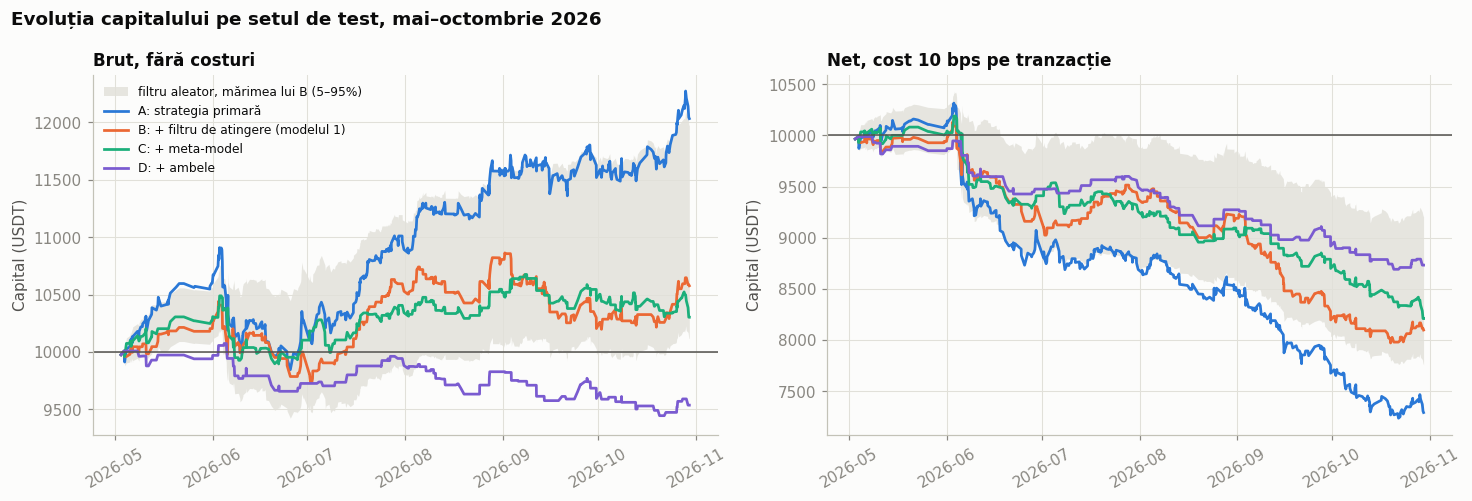

In [9]:
rng = np.random.default_rng(SEED)
def random_paths(n_keep, cost_bps, reps=N_RANDOM):
    g = TE["gross"].to_numpy() - cost_bps / 1e4; out = np.full((reps, len(TE)), np.nan)
    for r_ in range(reps):
        m = np.zeros(len(TE), bool); m[rng.choice(len(TE), n_keep, replace=False)] = True
        out[r_] = CAPITAL0 * np.cumprod(np.where(m, 1 + g, 1.0))
    return out

cols = [C["blue"], C["orange"], C["aqua"], C["purple"]]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharex=True)
for ax, cost in zip(axes, (0, MAIN_COST)):
    rp = random_paths(int(VARIANTS["B: + filtru de atingere (modelul 1)"].sum()), cost)
    ax.fill_between(TE["t0"], np.percentile(rp, 5, axis=0), np.percentile(rp, 95, axis=0), color=GRID, alpha=.8, lw=0, label="filtru aleator, mărimea lui B (5–95%)")
    for (k, m), col in zip(VARIANTS.items(), cols):
        g = TE["gross"].to_numpy() - cost / 1e4
        ax.plot(TE["t0"], CAPITAL0 * np.cumprod(np.where(m, 1 + g, 1.0)), color=col, label=k, lw=1.8)
    ax.axhline(CAPITAL0, color=INK2, lw=1)
    ax.set_title("Brut, fără costuri" if cost == 0 else f"Net, cost {cost} bps pe tranzacție"); ax.set_ylabel("Capital (USDT)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Evoluția capitalului pe setul de test, mai–octombrie 2026", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); plt.show()

**Ce arată graficul.**

* **Brut (stânga):** A urcă de la 10.000 la circa 12.000 USDT. B și C urcă mai puțin, iar D scade. B și C stau **în banda gri** a filtrelor aleatoare de aceeași mărime, deci nu aleg mai bine decât hazardul.
* **Net, 10 bps (dreapta):** toate curbele scad aproape continuu. A pierde cel mai mult pentru că tranzacționează cel mai des. B termină chiar în partea de jos a benzii aleatoare: tranzacționează la fel de des ca un filtru aleator și pierde cam la fel.

## 11. Aduce modelul de volatilitate un avantaj?

Trei comparații pentru fiecare filtru:

1. **Față de strategia nefiltrată, pe aceleași zile:** diferența randamentului brut mediu pe tranzacție, cu un interval de încredere de 95% obținut prin bootstrap pe zile (2.000 de eșantioane).
2. **Față de un filtru aleator de aceeași mărime:** în ce percentilă a 1.000 de filtre aleatoare se află randamentul mediu al filtrului real. Peste 95 ar fi un semnal; în jur de 50 înseamnă că filtrul nu alege mai bine decât hazardul.
3. **Mărimea mișcării:** randamentul absolut mediu, pentru a vedea dacă filtrul alege mișcări mai mari.

comparație,B față de A: filtrul de atingere,C față de A: meta-modelul,D față de C: atingerea adăugată peste meta-model
tranzacții păstrate,267 din 501,227 din 501,88 din 227
brut filtrat (bps),2.2,1.417,-5.289
brut de referință (bps),3.795,3.795,1.417
diferență (bps),-1.594,-2.378,-6.706
IC 95% jos,-5.563,-6.611,-14.967
IC 95% sus,1.925,1.756,0.698
percentila vs filtru aleator,19.9,12.6,3.6
|brut| filtrat (bps),37.423,37.424,40.533
|brut| de referință (bps),35.857,35.857,37.424
rata de atingere filtrat,0.622,0.546,0.693


Pe chintile ale probabilității de atingere (Q1 = cea mai mică):


,tranzacții,rata_atingere,rata_castig,brut_bps,abs_brut_bps
p_hit,,,,,
Q1,101,0.317,0.554,4.483,31.400
Q2,100,0.530,0.600,5.823,35.132
Q3,100,0.530,0.540,3.456,36.946
Q4,100,0.610,0.620,4.965,37.395
Q5,100,0.680,0.520,0.240,38.456


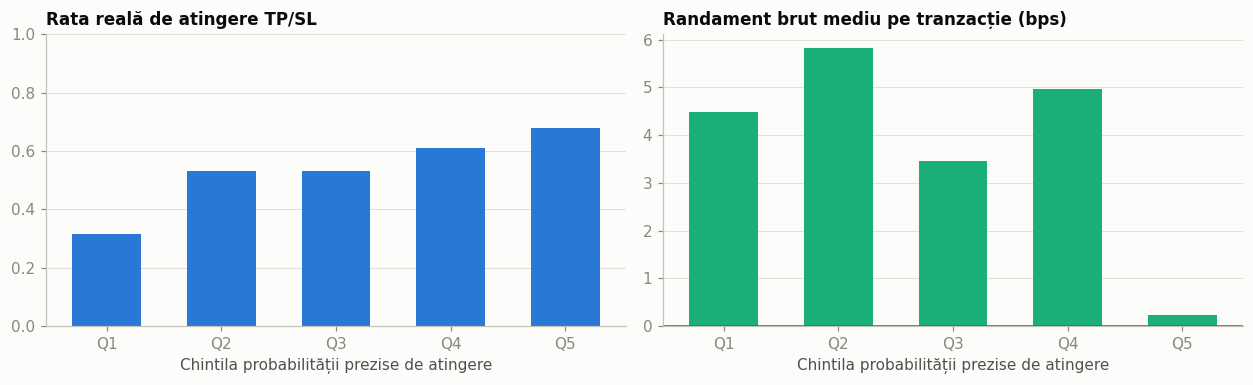

In [10]:
day_of = TE["t0"].dt.floor("D").to_numpy(); udays = np.unique(day_of); di = np.searchsorted(udays, day_of)
g_all = TE["gross"].to_numpy()
def boot_diff(m_a, m_b, reps=2000):
    sa, na = np.bincount(di, g_all * m_a, len(udays)), np.bincount(di, m_a.astype(float), len(udays))
    sb, nb = np.bincount(di, g_all * m_b, len(udays)), np.bincount(di, m_b.astype(float), len(udays))
    out = np.empty(reps); rr = np.random.default_rng(SEED + 5)
    for r_ in range(reps):
        w = np.bincount(rr.integers(0, len(udays), len(udays)), minlength=len(udays))
        out[r_] = (w @ sb) / (w @ nb) - (w @ sa) / (w @ na)
    return np.percentile(out, [2.5, 97.5])
rows = []
pairs = [("B față de A: filtrul de atingere", "B: + filtru de atingere (modelul 1)", "A: strategia primară"),
         ("C față de A: meta-modelul", "C: + meta-model", "A: strategia primară"),
         ("D față de C: atingerea adăugată peste meta-model", "D: + ambele", "C: + meta-model")]
for lab_, kb, ka in pairs:
    mb, ma = VARIANTS[kb], VARIANTS[ka]
    lo, hi = boot_diff(ma.astype(float), mb.astype(float))
    pool = np.flatnonzero(ma); nb_ = int(mb.sum())
    rnd = np.array([g_all[rng.choice(pool, nb_, replace=False)].mean() for _ in range(N_RANDOM)])
    rows.append({"comparație": lab_, "tranzacții păstrate": f"{nb_} din {int(ma.sum())}", "brut filtrat (bps)": 1e4 * g_all[mb].mean(), "brut de referință (bps)": 1e4 * g_all[ma].mean(),
                 "diferență (bps)": 1e4 * (g_all[mb].mean() - g_all[ma].mean()), "IC 95% jos": 1e4 * lo, "IC 95% sus": 1e4 * hi,
                 "percentila vs filtru aleator": 100 * np.mean(rnd < g_all[mb].mean()),
                 "|brut| filtrat (bps)": 1e4 * np.abs(g_all[mb]).mean(), "|brut| de referință (bps)": 1e4 * np.abs(g_all[ma]).mean(),
                 "rata de atingere filtrat": TE["hit"].to_numpy()[mb].mean(), "rata de atingere referință": TE["hit"].to_numpy()[ma].mean()})
ADV = pd.DataFrame(rows).set_index("comparație"); display(ADV.round(3).T)

# Does a higher attainment score mean a better trade? Quintiles of P(hit) on the test set.
q = pd.qcut(TE["p_hit"], 5, labels=[f"Q{i}" for i in range(1, 6)])
QT = TE.groupby(q, observed=True).agg(tranzacții=("gross", "size"), rata_atingere=("hit", "mean"), rata_castig=("win", "mean"),
                                      brut_bps=("gross", lambda x: 1e4 * x.mean()), abs_brut_bps=("gross", lambda x: 1e4 * x.abs().mean()))
print("Pe chintile ale probabilității de atingere (Q1 = cea mai mică):"); display(QT.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
axes[0].bar(QT.index.astype(str), QT["rata_atingere"], color=C["blue"], width=.6); axes[0].set_title("Rata reală de atingere TP/SL"); axes[0].set_ylim(0, 1)
axes[1].bar(QT.index.astype(str), QT["brut_bps"], color=[C["aqua"] if v > 0 else C["red"] for v in QT["brut_bps"]], width=.6)
axes[1].axhline(0, color=INK2, lw=1); axes[1].set_title("Randament brut mediu pe tranzacție (bps)")
for ax in axes:
    ax.set_xlabel("Chintila probabilității prezise de atingere"); ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

**Avantajul modelului de volatilitate: niciunul măsurabil.**

* **B față de A:** −1,6 bps brut pe tranzacție, IC 95% [−5,6; +1,9], percentila 20 față de filtrele aleatoare. Filtrul păstrează tranzacții care ating mai des bariera (62% față de 53%), dar mărimea mișcării abia crește (37,4 față de 35,9 bps), iar direcția nu se îmbunătățește.
* **De ce nu ajută atingerea?** Cu TP și SL simetrice, atingerea mai frecventă înseamnă că **ambele** bariere sunt atinse mai des. Dacă direcția este o monedă aruncată, câștigurile și pierderile cresc la fel și se anulează. Un model de volatilitate poate ajuta doar dacă avantajul strategiei depinde de volatilitate. Chintilele arată că nu e cazul: în Q5, unde rata de atingere este cea mai mare (68%), randamentul brut este cel mai mic (+0,2 bps).
* **D față de C:** adăugat peste meta-model, filtrul de atingere coboară randamentul la −5,3 bps, la percentila 4 față de filtrele aleatoare. Cu doar 88 de tranzacții, acesta este mai probabil zgomot decât un efect negativ real, dar în niciun caz nu este un avantaj.

## 12. `POST-HOC` Robustețe: pragul semnalului la 1,5 în loc de 2

**Adăugat după ce am văzut rezultatele de mai sus**, pentru că setul de test are doar câteva sute de tranzacții, iar intervalele sunt foarte largi. Un prag mai mic produce mai multe evenimente și deci mai multă putere statistică. Tot restul rămâne identic: aceleași bariere, feature-uri, parametri, split și metrici. Nu este o căutare de parametri: este o singură variantă, aleasă doar pentru mărimea eșantionului.

In [11]:
rows = []
for z_th in (Z_TH, 1.5):
    EVr, K0r = make_events(z_th); EVr, _ = label_events(EVr, K0r); Xr = make_X(EVr, K0r); trr, ter = split(EVr)
    _, ph = fit_predict("hit", FEATS, Xr, EVr, trr, ter); _, pm = fit_predict("win", FEATS, Xr, EVr, trr, ter)
    te_ = EVr[ter]; g = te_["gross"].to_numpy()
    di_ = np.searchsorted(np.unique(te_["t0"].dt.floor("D")), te_["t0"].dt.floor("D"))
    masks = {"A": np.ones(len(te_), bool), "B": ph >= 0.5, "C": pm >= 0.5, "D": (ph >= 0.5) & (pm >= 0.5)}
    r_ = {"prag |z|": z_th, "tranzacții test (A)": len(te_), "AUC model 1": roc_auc_score(te_["hit"], ph), "AUC model 2": roc_auc_score(te_["win"], pm)}
    for k, m in masks.items():
        r_[f"{k}: tranzacții"] = int(m.sum()); r_[f"{k}: brut (bps)"] = 1e4 * g[m].mean(); r_[f"{k}: net @10 (bps)"] = 1e4 * g[m].mean() - MAIN_COST
    rr = np.random.default_rng(SEED + 9); nd = di_.max() + 1; out = np.empty(2000)
    sa, na = np.bincount(di_, g, nd), np.bincount(di_, minlength=nd).astype(float)
    sb, nb = np.bincount(di_, g * masks["B"], nd), np.bincount(di_, masks["B"].astype(float), nd)
    for b_ in range(2000):
        w = np.bincount(rr.integers(0, nd, nd), minlength=nd); out[b_] = (w @ sb) / (w @ nb) - (w @ sa) / (w @ na)
    r_["B − A brut (bps)"] = 1e4 * (g[masks["B"]].mean() - g.mean()); r_["B − A IC 95%"] = f"[{1e4 * np.percentile(out, 2.5):.1f}, {1e4 * np.percentile(out, 97.5):.1f}]"
    r_["B: |brut| / A: |brut|"] = np.abs(g[masks["B"]]).mean() / np.abs(g).mean()
    rows.append(r_)
ROB = pd.DataFrame(rows).set_index("prag |z|").T
display(ROB)

prag |z|,2.0,1.5
tranzacții test (A),501,900
AUC model 1,0.635488,0.641308
AUC model 2,0.447913,0.504165
A: tranzacții,501,900
A: brut (bps),3.794652,1.070211
A: net @10 (bps),-6.205348,-8.929789
B: tranzacții,267,436
B: brut (bps),2.200402,1.472968
B: net @10 (bps),-7.799598,-8.527032
C: tranzacții,227,471


**La pragul 1,5 concluzia rămâne aceeași.** Cu 900 de tranzacții de test, strategia nefiltrată câștigă doar +1,1 bps brut. Filtrul de atingere dă +1,5 bps (B − A = +0,4, IC [−2,2; +3,1]), meta-modelul are AUC 0,50, iar combinația ajunge la +3,0 bps. Toate variantele pierd între 7 și 9 bps net la un cost de 10 bps. Diferența B − A schimbă semnul între cele două praguri, iar intervalele includ zero la ambele. Aceasta este semnătura unui efect absent, nu a unuia mic, dar real. AUC-ul modelului de atingere este stabil (0,64), deci modelul își face treaba; ce prezice el pur și simplu nu este valoros pentru această strategie.

## 13. Concluzie

| Întrebare | Răspuns |
|---|---|
| Funcționează modelul care prezice atingerea TP/SL? | **Da, ca model:** AUC 0,64, acuratețe 0,60 față de 0,53 |
| Funcționează meta-modelul? | **Nu:** AUC 0,45 la pragul 2 și 0,50 la pragul 1,5 |
| Aduce modelul de volatilitate un avantaj strategiei? | **Nu.** Randamentul brut pe tranzacție nu crește (−1,6 bps la pragul 2, +0,4 la pragul 1,5, ambele cu intervale care includ zero), iar filtrul nu bate filtrele aleatoare de aceeași mărime |
| Este vreo variantă profitabilă după costuri? | **Nu.** Toate pierd la 4 bps și pierd între 13% și 27% din capital în șase luni la 10 bps |

**De ce.** Un filtru de atingere selectează tranzacții în care prețul se mișcă mai mult, nu tranzacții în care se mișcă în direcția bună. Cu bariere simetrice și fără avantaj direcțional, mișcări mai mari înseamnă câștiguri și pierderi mai mari în aceeași proporție. Modelul de volatilitate ar ajuta doar o strategie al cărei avantaj crește cu volatilitatea, sau cu bariere asimetrice, unde atingerea uneia anume contează. Aici niciuna dintre condiții nu este îndeplinită.

**Limite.**

* **Eșantion mic:** 692 de tranzacții în train și 501 în test. Intervalele de încredere sunt de câțiva bps, comparabile cu efectele căutate.
* **Un singur split cronologic**, cu o schimbare de regim între train și test (reversal-ul pierde în train și câștigă în test).
* **Execuție simplificată:** intrare la prețul de închidere al barei de semnal, fără latență. Stop-ul la cel mai prost preț al barei este conservator, take-profit-ul la barieră este optimist. Fără funding.
* **Evenimentele cu goluri în fluxul de tranzacții** (14%) sunt excluse și apar mai des după mișcări mari.
* **Perioada de test a fost deja folosită** în notebook-urile anterioare, deci rezultatul este explorator.

**Jurnal de proces.**

* Designul din secțiunea 2 a fost scris înainte de orice rezultat.
* **Corectat după prima rulare:** fereastra de 24 de ore pentru `σ_15m` cerea minimum 2.000 de bare, ceea ce lăsa `σ` lipsă pe 15% din bare (în zilele liniștite) și elimina semnale fără legătură cu rezultatul lor. Pragul a fost coborât la 500 de bare. Am corectat și o eroare de overflow la spațierea evenimentelor.
* **Adăugat după rezultate (`POST-HOC`):** testul de robustețe cu pragul 1,5 (secțiunea 12), pentru mărimea eșantionului.

In [12]:
assert source_fingerprint() == FINGERPRINT_START, "Datele sursă s-au modificat în timpul rulării."
print(f"Datele sursă nu au fost modificate. Durata rulării: {(time.time() - T0) / 60:.1f} min; memorie maximă {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB; seed {SEED}.")

Datele sursă nu au fost modificate. Durata rulării: 0.1 min; memorie maximă 1.9 GB; seed 20261109.
